For example, if people invested following ranks: 1, 1, 1, 4, 5, 5, 7 multiplier last player gets 0.1
70, 70, 70, 50, 40, 40, 30
, they get the
. First three players get 0.9
for hit rate
and everybody in between gets linearly scaled

In [528]:
import numpy as np
import pandas as pd
import random
from statistics import NormalDist

def research(x):
    return 200_000 * np.log(1+x) / np.log(1 + 100)

def scale(x):
    return (7/100)*x

PROBABILITIES = {
    0: 0.01,
    48: 0.02,
    49: 0.05,
    50: 0.3,
    51: 0.45,
    52: 0.2,
    53: 0.15,
    54: 0.05,
    100: 0.01
}
# PROBABILITIES = {
#     50: 0.1,
#     51: 0.6,
# }
def simulate(N:int) -> list[int]: 
    # Returns a list of N integers corresponding to counts of submissions.
    scores = []
    for i in range(0,101):
        
        if PROBABILITIES.get(i):
            prob = PROBABILITIES.get(i)
            scores += [i]*int(N*prob)
        elif PROBABILITIES.get(i+1) or PROBABILITIES.get(i-1):
            prob = (PROBABILITIES.get(i+1) or PROBABILITIES.get(i-1))*0.2
            scores += [i]*int(N*prob)
        else:
            scores += [i]*random.randint(1,max(int(0.001*N),1))
        
        scores += [i]*random.randint(1,int(0.01*N)) # add a sprinkle of randomness to everything
    return scores
scores = simulate(5000)
df = pd.DataFrame({
    'Score':sorted(scores)
    })

df['Rank'] = df['Score'].rank(method='min', ascending=False)
max_rank = df['Rank'].max() # like 100
min_rank = df['Rank'].min() # should be 1
df['Speed_Multiplier'] = ((max_rank-df['Rank'])/(max_rank-min_rank))*0.8 + 0.1
newdf = {
    'Submission': df['Score'].unique(),
    'Rank': df['Rank'].unique(),
    'Speed_Multiplier': df['Speed_Multiplier'].unique(),
}

newdf = pd.DataFrame(newdf)


In [530]:
def speed(x):
    
    # df = pd.DataFrame({
    #     'Score':sorted(scores)
    #     })

    # df['Rank'] = df['Score'].rank(method='min', ascending=False)
    # max_rank = df['Rank'].max() # like 100
    # min_rank = df['Rank'].min() # should be 1
    # df['Speed_Multiplier'] = ((max_rank-df['Rank'])/(max_rank-min_rank))*0.8 + 0.1
    # newdf = {
    #     'Submission': df['Score'].unique(),
    #     'Rank': df['Rank'].unique(),
    #     'Speed_Multiplier': df['Speed_Multiplier'].unique(),
    # }
    # newdf = pd.DataFrame(newdf)
    speed = newdf.iloc[x].Speed_Multiplier
    return speed
    
    # Keep scalar return type when scalar input is provided



# def speed(x):
#     # highest speed = 0.9
#     # lowest receives 0.1
#     # Goal: slightly beat avg Nash
#     # If equal investments get same rank, we need to predict the Nash equilibrium and invest slightly more in one category to get a higher rank and thus a higher return on that category.
#     # returns not nescessarily to scale
#     x_arr = np.asarray(x)
#     base = np.round((0.8/100)*x_arr + 0.1, 1)
#     result = np.where(x_arr == 100, 0.9, np.where(x_arr == 99, 0.8, np.where(x_arr == 0, 0.1, base)))
    
#     # Keep scalar return type when scalar input is provided
#     if np.isscalar(x):
#         return float(result)
#     return result


def PnL(pct_research:int, pct_scale:int, pct_speed:int):
    
    total_pct = pct_research + pct_scale + pct_speed
    budget_used = (total_pct/100)*50_000
    res = research(pct_research)
    sca = scale(pct_scale)
    spe = speed(pct_speed)
    pnl = (res*sca*spe)-budget_used
    
    # Works for both scalar inputs and NumPy arrays
    return pnl

best = -1.0
best_d = [0,0,0]
for r in range(1,101):
    for sc in range (1, 100-r):
        for sp in range(0,100-r-sc):
            
            #nr = pd.DataFrame([{'pct_research': r, 'pct_scale': sc, 'pct_speed': sp, 'PnL': }])
            profit = PnL(r,sc,sp)
            #print(f"Testing: ({r,sc,sp})  | PnL = {int(PnL(r,sc,sp))} | CURRENT BEST = {best,best_d}")
            #print(profit)
            if int(profit) > int(best):
                best = profit
                best_d = [r,sc,sp]

print(best)
print(best_d)
print(PnL(best_d[0],best_d[1],best_d[2]))

154058.80020852643
[12, 34, 53]
154058.80020852643


In [ ]:
def speed(x):
    
    # df = pd.DataFrame({
    #     'Score':sorted(scores)
    #     })

    # df['Rank'] = df['Score'].rank(method='min', ascending=False)
    # max_rank = df['Rank'].max() # like 100
    # min_rank = df['Rank'].min() # should be 1
    # df['Speed_Multiplier'] = ((max_rank-df['Rank'])/(max_rank-min_rank))*0.8 + 0.1
    # newdf = {
    #     'Submission': df['Score'].unique(),
    #     'Rank': df['Rank'].unique(),
    #     'Speed_Multiplier': df['Speed_Multiplier'].unique(),
    # }
    # newdf = pd.DataFrame(newdf)
    speed = newdf.iloc[x].Speed_Multiplier
    print(speed)
    return speed
    
    # Keep scalar return type when scalar input is provided



# def speed(x):
#     # highest speed = 0.9
#     # lowest receives 0.1
#     # Goal: slightly beat avg Nash
#     # If equal investments get same rank, we need to predict the Nash equilibrium and invest slightly more in one category to get a higher rank and thus a higher return on that category.
#     # returns not nescessarily to scale
#     x_arr = np.asarray(x)
#     base = np.round((0.8/100)*x_arr + 0.1, 1)
#     result = np.where(x_arr == 100, 0.9, np.where(x_arr == 99, 0.8, np.where(x_arr == 0, 0.1, base)))
    
#     # Keep scalar return type when scalar input is provided
#     if np.isscalar(x):
#         return float(result)
#     return result


def PnL(pct_research:int, pct_scale:int, pct_speed:int):
    
    total_pct = pct_research + pct_scale + pct_speed
    budget_used = (total_pct/100)*50_000
    res = research(pct_research)
    sca = scale(pct_scale)
    spe = speed(pct_speed)
    pnl = (res*sca*spe)-budget_used
    
    # Works for both scalar inputs and NumPy arrays
    return pnl

best = -1
best_d = (0,0,0)
for r in range(1,101):
    for sc in range (1, 100-r):
        for sp in range(0,100-r-sc):
            
            #nr = pd.DataFrame([{'pct_research': r, 'pct_scale': sc, 'pct_speed': sp, 'PnL': }])
            profit = PnL(r,sc,sp)
            #print(f"Testing: ({r,sc,sp})  | PnL = {int(PnL(r,sc,sp))}")
            #print(profit)
            if profit > best:
                best = profit
                best_d = (r,sp,sc)

print(best)
print(best_d)
print(PnL(1,1,52))
            
            

12, 53, 34 -> 99% used

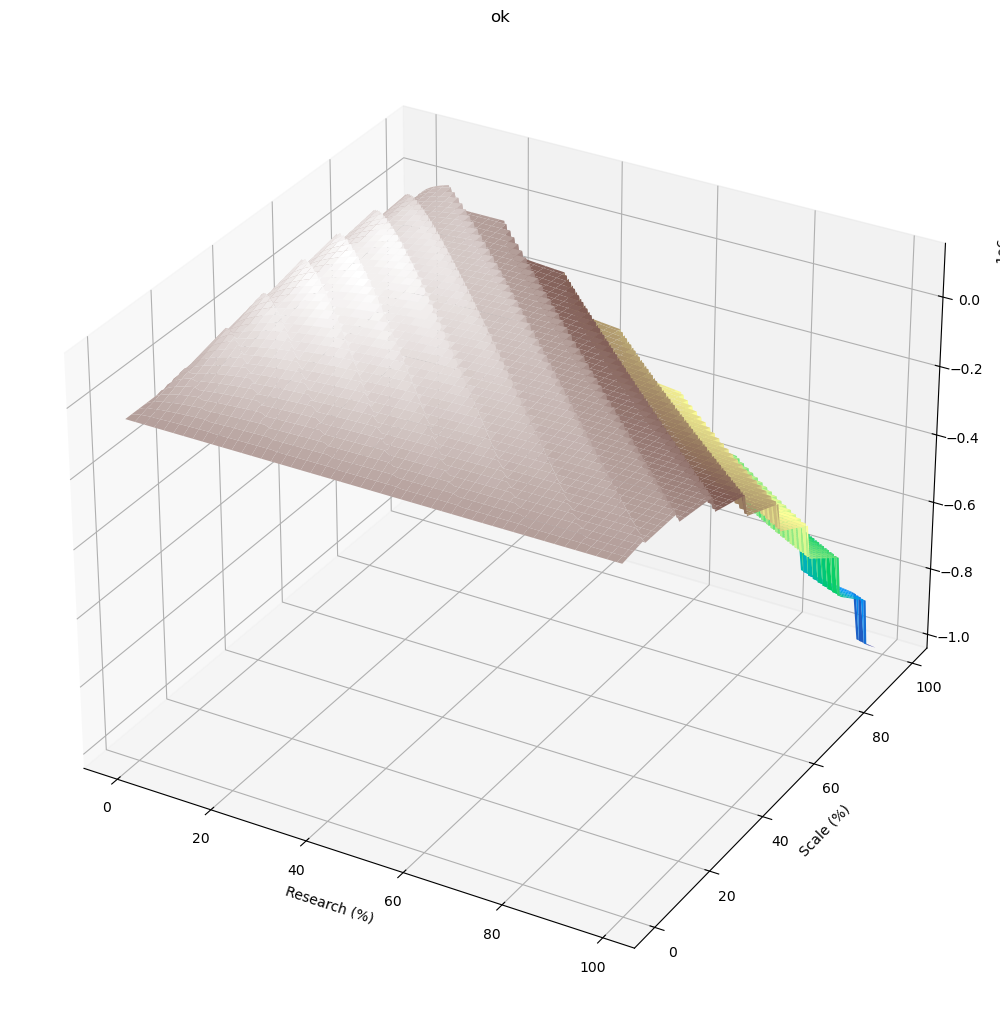

In [ ]:
import matplotlib.pyplot as plt
import numpy as np


import matplotlib as mpl

from matplotlib import cm

plt.style.use('_mpl-gallery')

# Make data
X = np.arange(0, 100, 1)
Y = np.arange(0, 100, 1)
X, Y = np.meshgrid(X, Y)
Z = PnL(X, Y, 100-X-Y)

# Plot the surface
fig, ax = plt.subplots(subplot_kw={"projection": "3d"}, figsize=(10,10))
ax.plot_surface(X, Y, Z, cmap=cm.terrain)

plt.xlabel("Research (%)")
plt.ylabel("Scale (%)")


plt.title("ok")
plt.show()

In [409]:

data = {'Score': [0,0,0, 1, 2, 2, 3, 4, 49, 50, 51, 52, 52, 53, 96, 85, 90, 100, 100]}
rng = np.random.default_rng()
samples = rng.normal(loc=50, scale=10.0, size=100)
samples = np.concatenate([samples,[0,0,0,0,0,0,49,50,51,52,52,52,52,52,52,53,53,53,54,55,56,99,99,99,100,100,100]])
data = {'Score': sorted(samples)}
df = pd.DataFrame(data)

# Default ranking (average method, ascending)
df['Default_Rank'] = df['Score'].rank()

# Dense ranking (no gaps, descending)
df['Min_Rank'] = df['Score'].rank(method='min', ascending=False)
df



,Score,Default_Rank,Min_Rank
0,0.0,3.5,122.0
1,0.0,3.5,122.0
2,0.0,3.5,122.0
3,0.0,3.5,122.0
4,0.0,3.5,122.0
...,...,...,...
122,99.0,123.0,4.0
123,99.0,123.0,4.0
124,100.0,126.0,1.0
125,100.0,126.0,1.0


5600 teams -> 90% participation ->

1% at 0 (not optimal at all)
10% between 1 and 47
40% between 48 and 52
10% figure out to bid 53
5% bid 54
rest between 54 and 99
1% at 100 (also not optimal at all since PnL = 0)

In [ ]:
import random

PROBABILITIES_SMART = {
    0: 0,
    1: 0.01,
    48: 0.02,
    49: 0.05,
    50: 0.3,
    51: 0.25,
    52: 0.2,
    53: 0.15,
    99: 0.01,
    100: 0
}

PROBABILITIES = {
    0: 0.01,
    48: 0.02,
    49: 0.05,
    50: 0.3,
    51: 0.25,
    52: 0.2,
    53: 0.15,
    100: 0.01
}
def simulate(N:int) -> list[int]: 
    # Returns a list of N integers corresponding to counts of submissions.
    scores = []
    for i in range(0,101):
        
        if PROBABILITIES.get(i):
            prob = PROBABILITIES.get(i)
            scores += [i]*int(N*prob)
        elif PROBABILITIES.get(i+1) or PROBABILITIES.get(i-1):
            prob = (PROBABILITIES.get(i+1) or PROBABILITIES.get(i-1))*0.2
            scores += [i]*int(N*prob)
        else:
            scores += [i]*random.randint(1,max(int(0.001*N),1))
        
        #scores += [i]*random.randint(1,int(0.01*10000))
    return scores

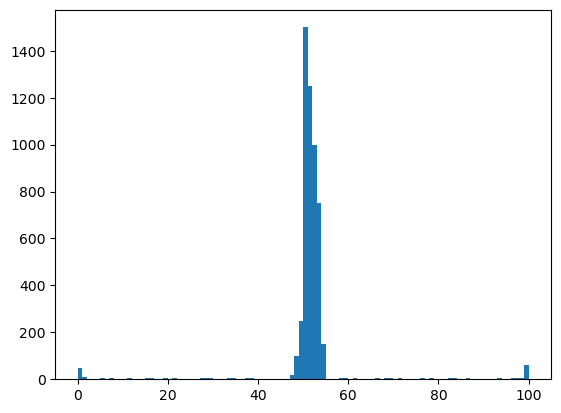

0.40067415730337086

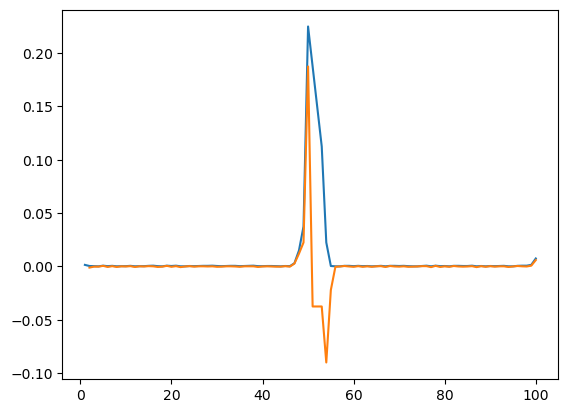

In [455]:
import math
import random    
scores = simulate(5000)
df = pd.DataFrame({
    'Score':sorted(scores)
    })

#df = df.value_counts().sort_index()


import matplotlib.pyplot as plt
fig = plt.subplots(1,1)
plt.hist(scores, bins=100)
plt.show()
df.value_counts().sort_index().iloc[40:60]

df['Rank'] = df['Score'].rank(method='min', ascending=False)
max_rank = df['Rank'].max() # like 100
min_rank = df['Rank'].min() # should be 1
df['Speed_Multiplier'] = ((max_rank-df['Rank'])/(max_rank-min_rank))*0.8 + 0.1
# newdf = df.value_counts().sort_index()
# # newdf = pd.DataFrame({
# #     'Submission': df.value_counts().sort_index(),
# #     'Count': df.value_counts().sort_index()
# # })
# print(newdf)
# df['Score'].unique()



newdf = {
    'Submission': df['Score'].unique(),
    'Rank': df['Rank'].unique(),
    'Speed_Multiplier': df['Speed_Multiplier'].unique(),
}
newdf = pd.DataFrame(newdf)
newdf['d_speed'] = newdf['Speed_Multiplier'].diff()
newdf['d2_speed'] = newdf['d_speed'].diff()
newdf
newdf['d_speed']
newdf['d_speed'].plot()
newdf['d2_speed'].plot()
newdf.iloc[50].Speed_Multiplier

In [400]:

#data = {'Score': [70,70,70,50,40,40,30]}
#data = {'Score': [90, 20, 10, 0]}
data = {'Score': scores}
df = pd.DataFrame(data)

# Default ranking (average method, ascending)
#df['Default_Rank'] = df['Score'].rank()

# Dense ranking (no gaps, descending)
df['Rank'] = df['Score'].rank(method='min', ascending=False)
max_rank = df['Rank'].max() # like 100
min_rank = df['Rank'].min() # should be 1
df['Speed_Multiplier'] = ((max_rank-df['Rank'])/(max_rank-min_rank))*0.8 + 0.1
df
# EXCPECTED: 1, 1, 1, 4, 5, 5, 7
import plotly.express as px
fig = px.scatter(df, 'Rank', 'Speed_Multiplier')
fig.show()


In [111]:

# highest speed = 0.9
# lowest receives 0.1
# Goal: slightly beat avg Nash
# If equal investments get same rank, we need to predict the Nash equilibrium and invest slightly more in one category to get a higher rank and thus a higher return on that category.
# returns not nescessarily to scale
#data = {'Score': [0,0,0, 1, 2, 2, 3, 4, 49, 50, 51, 52, 52, 53, 96, 85, 90, 100, 100]}
rng = np.random.default_rng()
samples = rng.normal(loc=50, scale=5.0, size=100)
samples = np.concatenate([samples,[0,0,0,0,0,0,49,50,51,52,52,52,52,52,52,53,53,53,54,55,56,99,99,99,100,100,100]])
samples = np.concatenate([samples,[101]])
data = {'Score': sorted(samples)}
df = pd.DataFrame(data)

# Default ranking (average method, ascending)
df['Default_Rank'] = df['Score'].rank()

# Dense ranking (no gaps, descending)
df['Min_Rank'] = df['Score'].rank(method='min', ascending=False)
max_rank = df['Min_Rank'].max()
min_rank = df['Min_Rank'].min()
rank = df.query(f'Score == 101')["Min_Rank"].item()
rank

1.0

Best Outcome:
156665.9982049386
(16, 35, 48)

In [ ]:
N = NormalDist(50,1)

NormalDist(mu=50.0, sigma=1.0)